# Funktionen

## 07 – Funktionsmanipulationen

**Voraussetzungen:** [01_Funktionsbegriff](01_Funktionsbegriff_Grundlagen.ipynb), [03_Lineare_Quadratische](03_Lineare_Quadratische_Funktionen.ipynb)

### Lernziele

- Funktionen **verschieben** (horizontal und vertikal)
- Funktionen **strecken und stauchen** (vertikal und horizontal)
- Funktionen **spiegeln** (an der x-Achse und der y-Achse)
- **Zusammengesetzte Transformationen** in der richtigen Reihenfolge anwenden
- Den Effekt jeder Manipulation am Graphen ablesen

---

### 1. Übersicht: Transformationen

Ausgehend von einer bekannten Funktion $f(x)$ lassen sich neue Funktionen erzeugen, indem man am **Argument** (innerhalb von $f$) oder am **Funktionswert** (außerhalb von $f$) Änderungen vornimmt.

| Transformation | Formel | Wirkung |
|----------------|--------|---------|
| Verschiebung nach oben | $f(x) + c$ | Graph wandert $c$ Einheiten nach oben |
| Verschiebung nach unten | $f(x) - c$ | Graph wandert $c$ Einheiten nach unten |
| Verschiebung nach rechts | $f(x - h)$ | Graph wandert $h$ Einheiten nach rechts |
| Verschiebung nach links | $f(x + h)$ | Graph wandert $h$ Einheiten nach links |
| Vertikale Streckung | $a \cdot f(x)$, $a > 1$ | Graph wird vertikal gestreckt |
| Vertikale Stauchung | $a \cdot f(x)$, $0 < a < 1$ | Graph wird vertikal gestaucht |
| Horizontale Stauchung | $f(b \cdot x)$, $b > 1$ | Graph wird horizontal gestaucht |
| Horizontale Streckung | $f(b \cdot x)$, $0 < b < 1$ | Graph wird horizontal gestreckt |
| Spiegelung an x-Achse | $-f(x)$ | Vorzeichen der y-Werte wird umgekehrt |
| Spiegelung an y-Achse | $f(-x)$ | Vorzeichen der x-Werte wird umgekehrt |

**Faustregel:**
- Änderungen **außen** (an $f$) wirken **vertikal** und **wie erwartet** (+ → nach oben)
- Änderungen **innen** (am Argument $x$) wirken **horizontal** und **gegenläufig** ($x - h$ → nach rechts)

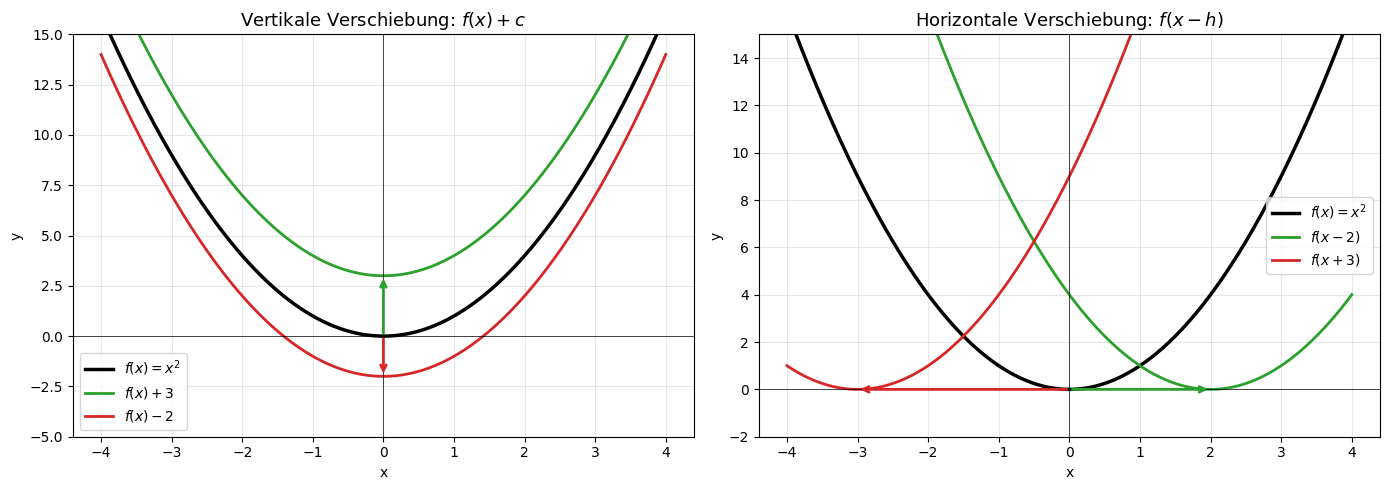

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# --- Verschiebungen ---

def visualisiere_verschiebungen():
    """Zeigt horizontale und vertikale Verschiebungen."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    x = np.linspace(-4, 4, 300)
    f = x**2  # Referenzfunktion

    # --- Links: Vertikale Verschiebung f(x) + c ---
    ax = axes[0]
    ax.plot(x, f, 'k-', linewidth=2.5, label=r"$f(x) = x^2$")
    for c, farbe, stil in [(3, '#2ca02c', '-'), (-2, '#d62728', '-')]:
        ax.plot(x, f + c, color=farbe, linewidth=2, linestyle=stil,
                label=f"$f(x) {'+' if c > 0 else ''}{c}$")
        ax.annotate('', xy=(0, c), xytext=(0, 0),
                    arrowprops=dict(arrowstyle='->', color=farbe, lw=2))
    ax.set_title("Vertikale Verschiebung: $f(x) + c$", fontsize=13)
    ax.legend(fontsize=10)
    ax.set_ylim(-5, 15)

    # --- Rechts: Horizontale Verschiebung f(x - h) ---
    ax = axes[1]
    ax.plot(x, f, 'k-', linewidth=2.5, label=r"$f(x) = x^2$")
    for h, farbe, beschriftung in [(2, '#2ca02c', 'f(x-2)'), (-3, '#d62728', 'f(x+3)')]:
        ax.plot(x, (x - h)**2, color=farbe, linewidth=2,
                label=f"${beschriftung}$")
        ax.annotate('', xy=(h, 0), xytext=(0, 0),
                    arrowprops=dict(arrowstyle='->', color=farbe, lw=2))
    ax.set_title(r"Horizontale Verschiebung: $f(x - h)$", fontsize=13)
    ax.legend(fontsize=10)
    ax.set_ylim(-2, 15)

    for ax in axes:
        ax.grid(True, alpha=0.3)
        ax.axhline(0, color='black', linewidth=0.5)
        ax.axvline(0, color='black', linewidth=0.5)
        ax.set_xlabel("x")
        ax.set_ylabel("y")

    plt.tight_layout()
    plt.show()

visualisiere_verschiebungen()

### 2. Streckung und Stauchung

#### Vertikale Streckung/Stauchung: $a \cdot f(x)$

Der Faktor $a$ multipliziert jeden **y-Wert**:
- $|a| > 1$: Der Graph wird in y-Richtung **gestreckt** (steiler)
- $0 < |a| < 1$: Der Graph wird in y-Richtung **gestaucht** (flacher)
- Nullstellen bleiben unverändert (denn $a \cdot 0 = 0$)

#### Horizontale Streckung/Stauchung: $f(b \cdot x)$

Der Faktor $b$ ändert das **Argument** - die Wirkung ist gegenläufig:
- $|b| > 1$: Der Graph wird horizontal **gestaucht** (zusammengedrückt)
- $0 < |b| < 1$: Der Graph wird horizontal **gestreckt** (auseinandergezogen)

Bei periodischen Funktionen wie $\sin(x)$ beeinflusst $b$ die **Periode**: $T = \frac{2\pi}{|b|}$.

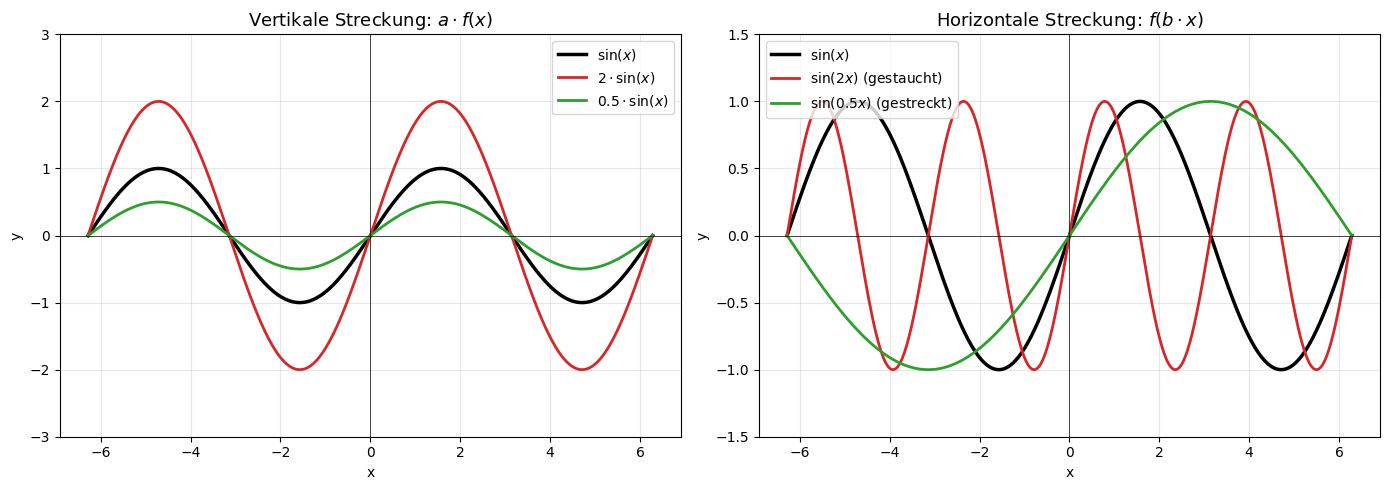

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# --- Streckung und Stauchung ---

def visualisiere_streckung():
    """Zeigt vertikale und horizontale Streckung/Stauchung."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    x = np.linspace(-2*np.pi, 2*np.pi, 500)

    # --- Links: Vertikale Streckung a·f(x) ---
    ax = axes[0]
    ax.plot(x, np.sin(x), 'k-', linewidth=2.5, label=r"$\sin(x)$")
    for a, farbe in [(2, '#d62728'), (0.5, '#2ca02c')]:
        ax.plot(x, a * np.sin(x), color=farbe, linewidth=2,
                label=f"${a} \\cdot \\sin(x)$")
    ax.set_title(r"Vertikale Streckung: $a \cdot f(x)$", fontsize=13)
    ax.legend(fontsize=10)
    ax.set_ylim(-3, 3)

    # --- Rechts: Horizontale Stauchung/Streckung f(b·x) ---
    ax = axes[1]
    ax.plot(x, np.sin(x), 'k-', linewidth=2.5, label=r"$\sin(x)$")
    for b, farbe, hinweis in [(2, '#d62728', 'gestaucht'), (0.5, '#2ca02c', 'gestreckt')]:
        ax.plot(x, np.sin(b * x), color=farbe, linewidth=2,
                label=f"$\\sin({b}x)$ ({hinweis})")
    ax.set_title(r"Horizontale Streckung: $f(b \cdot x)$", fontsize=13)
    ax.legend(fontsize=10)
    ax.set_ylim(-1.5, 1.5)

    for ax in axes:
        ax.grid(True, alpha=0.3)
        ax.axhline(0, color='black', linewidth=0.5)
        ax.axvline(0, color='black', linewidth=0.5)
        ax.set_xlabel("x")
        ax.set_ylabel("y")

    plt.tight_layout()
    plt.show()

visualisiere_streckung()

### 3. Spiegelungen

| Spiegelung | Formel | Wirkung |
|------------|--------|---------|
| An der **x-Achse** | $-f(x)$ | Alle y-Werte ändern das Vorzeichen |
| An der **y-Achse** | $f(-x)$ | Der Graph wird links-rechts vertauscht |
| Am **Ursprung** | $-f(-x)$ | Beide Spiegelungen kombiniert |

**Zusammenhang mit Symmetrie:**
- $f(-x) = f(x)$: Die Funktion ist **gerade** (symmetrisch zur y-Achse) → Spiegelung an y-Achse ändert nichts
- $f(-x) = -f(x)$: Die Funktion ist **ungerade** (punktsymmetrisch zum Ursprung) → Spiegelung am Ursprung ändert nichts

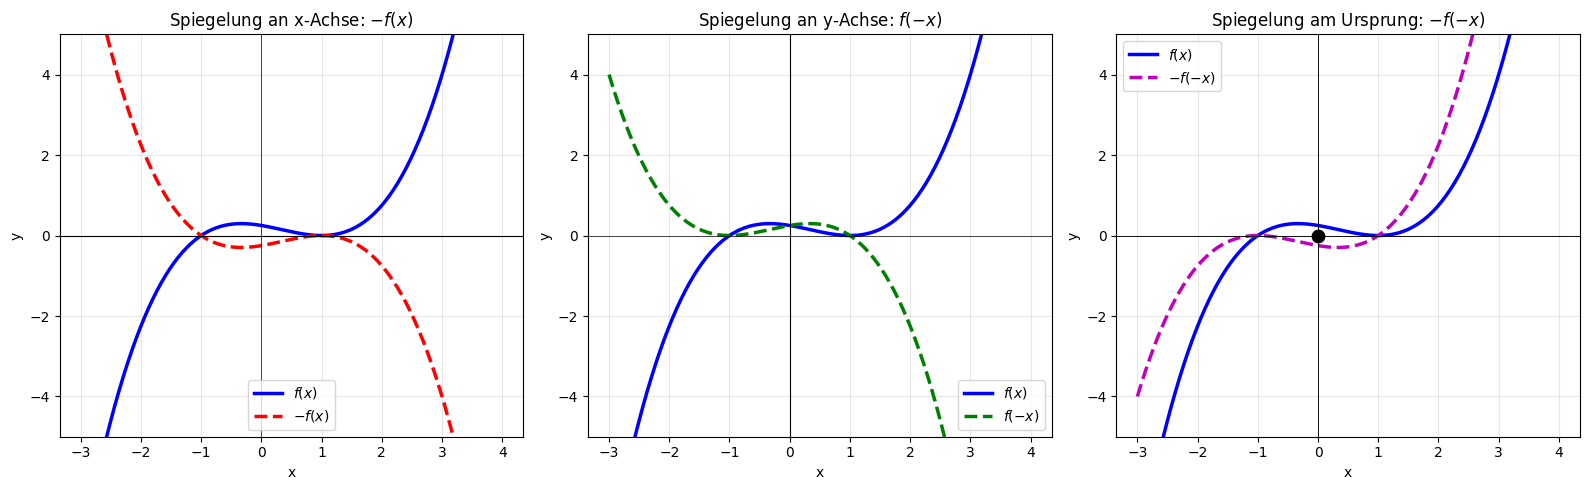

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# --- Spiegelungen ---

def visualisiere_spiegelungen():
    """Zeigt Spiegelung an x-Achse, y-Achse und Ursprung."""
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    x = np.linspace(-3, 4, 300)
    # Referenzfunktion: asymmetrisch, damit Spiegelungen sichtbar sind
    f = (x - 1)**2 * (x + 1) / 4

    # --- Spiegelung an x-Achse: -f(x) ---
    ax = axes[0]
    ax.plot(x, f, 'b-', linewidth=2.5, label=r"$f(x)$")
    ax.plot(x, -f, 'r--', linewidth=2.5, label=r"$-f(x)$")
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_title("Spiegelung an x-Achse: $-f(x)$", fontsize=12)
    ax.legend(fontsize=10)

    # --- Spiegelung an y-Achse: f(-x) ---
    ax = axes[1]
    f_neg = (-x - 1)**2 * (-x + 1) / 4
    ax.plot(x, f, 'b-', linewidth=2.5, label=r"$f(x)$")
    ax.plot(x, f_neg, 'g--', linewidth=2.5, label=r"$f(-x)$")
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_title("Spiegelung an y-Achse: $f(-x)$", fontsize=12)
    ax.legend(fontsize=10)

    # --- Spiegelung am Ursprung: -f(-x) ---
    ax = axes[2]
    ax.plot(x, f, 'b-', linewidth=2.5, label=r"$f(x)$")
    ax.plot(x, -f_neg, 'm--', linewidth=2.5, label=r"$-f(-x)$")
    ax.axhline(0, color='black', linewidth=0.5)
    ax.axvline(0, color='black', linewidth=0.5)
    ax.scatter(0, 0, color='black', s=80, zorder=5)
    ax.set_title("Spiegelung am Ursprung: $-f(-x)$", fontsize=12)
    ax.legend(fontsize=10)

    for ax in axes:
        ax.grid(True, alpha=0.3)
        ax.axhline(0, color='black', linewidth=0.5)
        ax.axvline(0, color='black', linewidth=0.5)
        ax.set_xlabel("x")
        ax.set_ylabel("y")
        ax.set_ylim(-5, 5)

    plt.tight_layout()
    plt.show()

visualisiere_spiegelungen()

### 4. Zusammengesetzte Transformationen

Die allgemeine Form einer transformierten Funktion:

$$g(x) = a \cdot f\bigl(b(x - h)\bigr) + c$$

| Parameter | Wirkung |
|-----------|--------- |
| $h$ | Horizontale Verschiebung (nach rechts für $h > 0$) |
| $b$ | Horizontale Skalierung (Stauchung für $\|b\| > 1$) |
| $a$ | Vertikale Skalierung (Streckung für $\|a\| > 1$) |
| $c$ | Vertikale Verschiebung (nach oben für $c > 0$) |

**Reihenfolge der Anwendung** (von innen nach außen):

1. Horizontale Verschiebung: $x \to x - h$
2. Horizontale Skalierung: $x \to b \cdot x$
3. Anwendung von $f$
4. Vertikale Skalierung: $y \to a \cdot y$
5. Vertikale Verschiebung: $y \to y + c$

**Beispiel:** $g(x) = 2\sin\bigl(3(x - \frac{\pi}{4})\bigr) + 1$

| Schritt | Transformation | Numerisch |
|---------|---------------|-------- |
| 1 | Verschiebung nach rechts | um $\frac{\pi}{4}$ |
| 2 | Horizontale Stauchung | Faktor 3 → Periode $\frac{2\pi}{3}$ |
| 3 | Vertikale Streckung | Faktor 2 → Amplitude 2 |
| 4 | Verschiebung nach oben | um 1 |

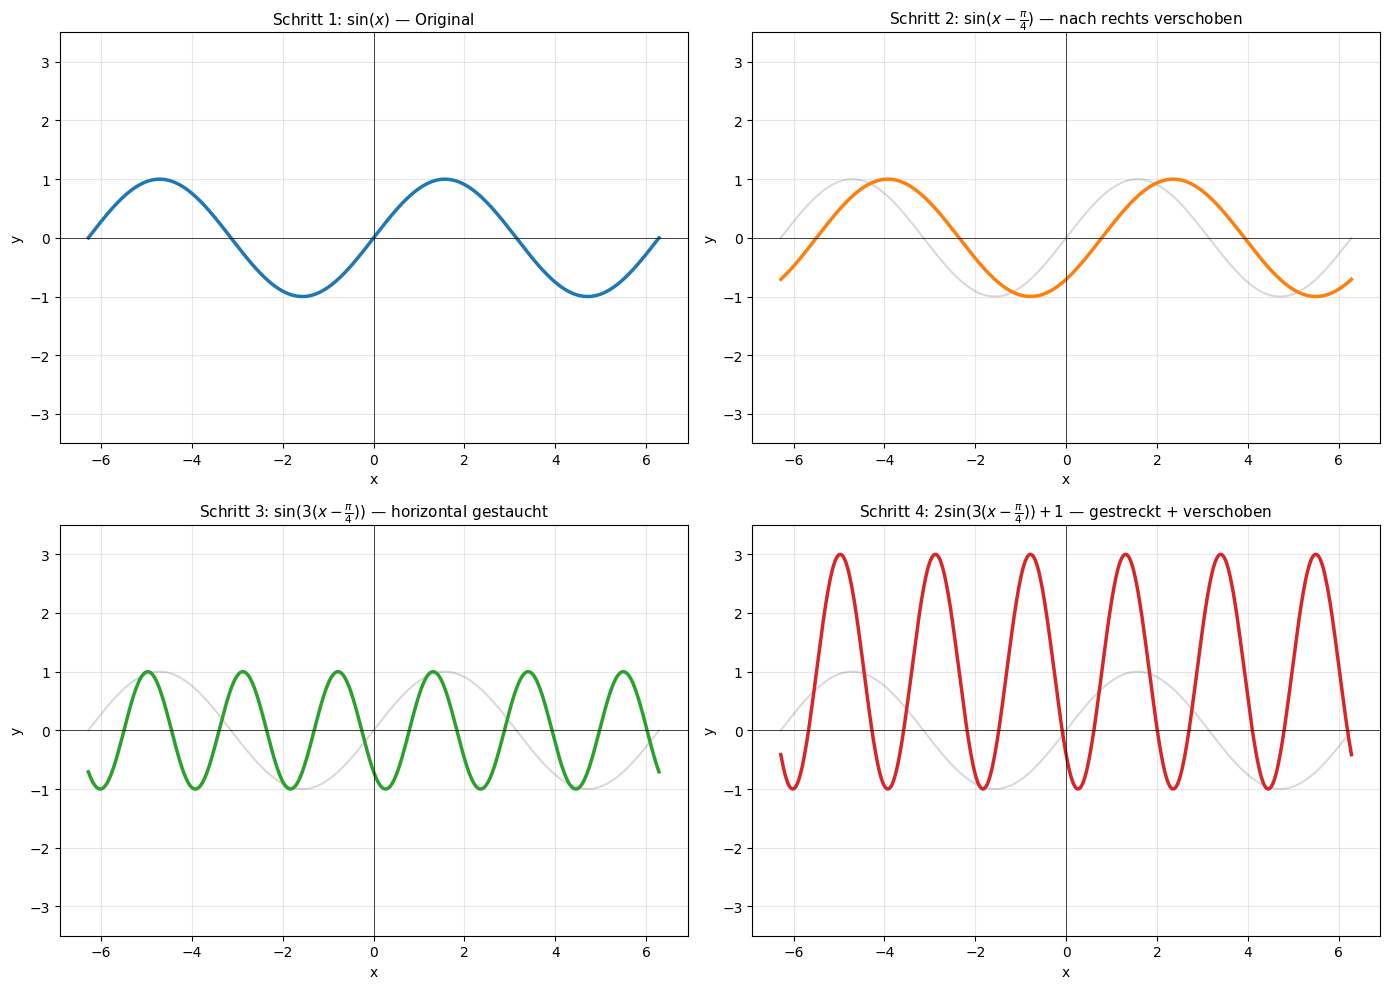

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# --- Zusammengesetzte Transformation Schritt für Schritt ---

def visualisiere_zusammengesetzte_transformation():
    """Zeigt schrittweise Aufbau von g(x) = 2·sin(3(x - π/4)) + 1."""
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    x = np.linspace(-2*np.pi, 2*np.pi, 500)

    schritte = [
        (np.sin(x), r"$\sin(x)$ - Original"),
        (np.sin(x - np.pi/4), r"$\sin(x - \frac{\pi}{4})$ - nach rechts verschoben"),
        (np.sin(3*(x - np.pi/4)), r"$\sin(3(x - \frac{\pi}{4}))$ - horizontal gestaucht"),
        (2*np.sin(3*(x - np.pi/4)) + 1, r"$2\sin(3(x - \frac{\pi}{4})) + 1$ - gestreckt + verschoben")
    ]

    farben = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

    for idx, ((y, titel), ax) in enumerate(zip(schritte, axes.flat)):
        # Referenz immer grau im Hintergrund
        ax.plot(x, np.sin(x), 'k-', alpha=0.15, linewidth=1.5)
        ax.plot(x, y, color=farben[idx], linewidth=2.5)
        ax.set_title(f"Schritt {idx+1}: {titel}", fontsize=11)
        ax.grid(True, alpha=0.3)
        ax.axhline(0, color='black', linewidth=0.5)
        ax.axvline(0, color='black', linewidth=0.5)
        ax.set_xlabel("x")
        ax.set_ylabel("y")
        ax.set_ylim(-3.5, 3.5)

    plt.tight_layout()
    plt.show()

visualisiere_zusammengesetzte_transformation()

### 5. Betrag und Verkettung

Zwei weitere häufige Manipulationen:

| Transformation | Formel | Wirkung |
|----------------|--------|---------|
| Betrag von $f$ | $\|f(x)\|$ | Negative y-Werte werden nach oben geklappt |
| Betrag von $x$ | $f(\|x\|)$ | Der Graph für $x \ge 0$ wird an der y-Achse gespiegelt |

**Verkettung:** Bei $g(f(x))$ wird zuerst $f$ angewendet, dann $g$.

Beispiel: $|\sin(x)|$ klappt alle negativen Sinuswerte nach oben → nur positive Werte, doppelte Frequenz.

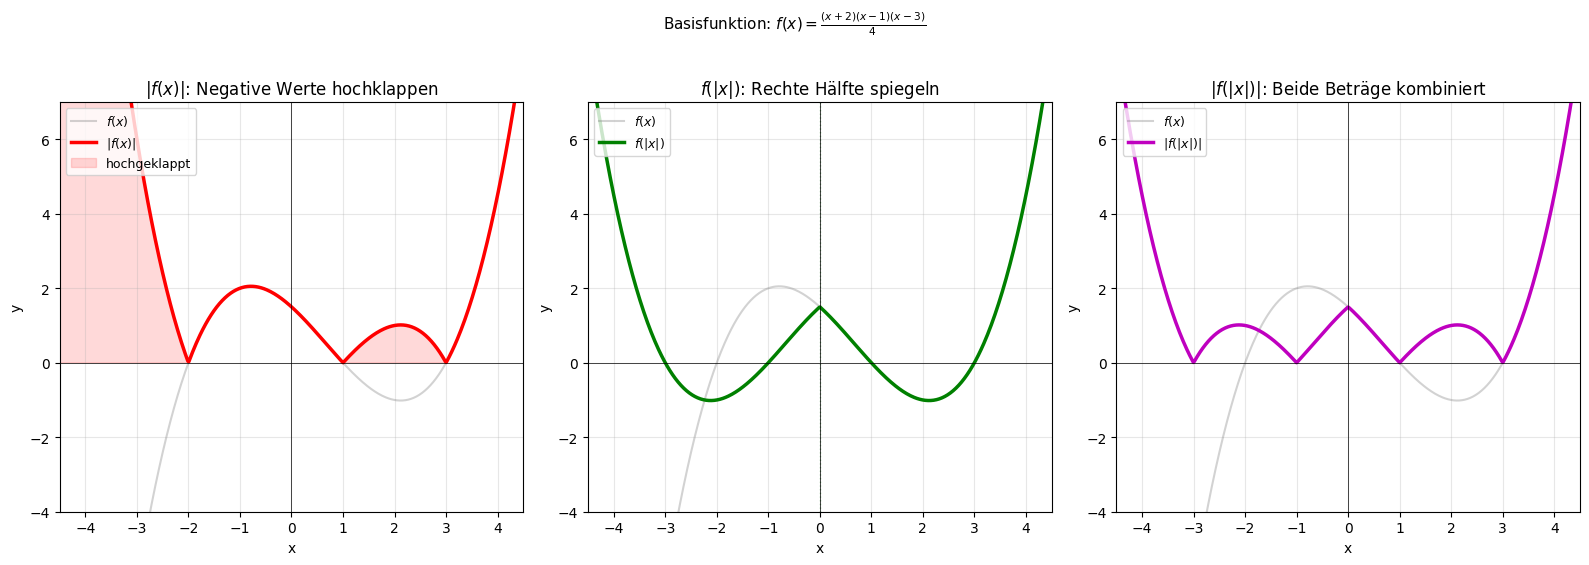

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# --- Betrag-Transformationen ---

def visualisiere_betrag():
    """Zeigt |f(x)|, f(|x|) und |f(|x|)| Transformationen."""
    fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))

    # Basisfunktion: f(x) = (x+2)(x-1)(x-3)/4  → Nullstellen bei -2, 1, 3
    x = np.linspace(-4.5, 4.5, 500)
    f = lambda t: (t + 2) * (t - 1) * (t - 3) / 4

    f_x = f(x)
    abs_f_x = np.abs(f_x)
    f_abs_x = f(np.abs(x))
    abs_f_abs_x = np.abs(f_abs_x)

    ref_style = dict(color='gray', alpha=0.35, linewidth=1.5, linestyle='-')

    # --- Links: |f(x)| ---
    ax = axes[0]
    ax.plot(x, f_x, **ref_style, label=r"$f(x)$")
    ax.plot(x, abs_f_x, 'r-', linewidth=2.5, label=r"$|f(x)|$")
    # Nur den hochgeklappten Teil markieren (von 0 bis |f(x)|, wo f(x) < 0)
    mask_neg = f_x < 0
    ax.fill_between(x, 0, abs_f_x, where=mask_neg,
                    color='red', alpha=0.15, label="hochgeklappt")
    ax.set_title(r"$|f(x)|$: Negative Werte hochklappen", fontsize=12)
    ax.legend(fontsize=9, loc='upper left')

    # --- Mitte: f(|x|) ---
    ax = axes[1]
    ax.plot(x, f_x, **ref_style, label=r"$f(x)$")
    ax.plot(x, f_abs_x, 'g-', linewidth=2.5, label=r"$f(|x|)$")
    ax.axvline(0, color='green', linestyle=':', alpha=0.4, linewidth=1)
    ax.set_title(r"$f(|x|)$: Rechte Hälfte spiegeln", fontsize=12)
    ax.legend(fontsize=9, loc='upper left')

    # --- Rechts: |f(|x|)| (Kombination) ---
    ax = axes[2]
    ax.plot(x, f_x, **ref_style, label=r"$f(x)$")
    ax.plot(x, abs_f_abs_x, 'm-', linewidth=2.5, label=r"$|f(|x|)|$")
    ax.set_title(r"$|f(|x|)|$: Beide Beträge kombiniert", fontsize=12)
    ax.legend(fontsize=9, loc='upper left')

    for ax in axes:
        ax.grid(True, alpha=0.3)
        ax.axhline(0, color='black', linewidth=0.5)
        ax.axvline(0, color='black', linewidth=0.5)
        ax.set_xlabel("x")
        ax.set_ylabel("y")
        ax.set_xlim(-4.5, 4.5)
        ax.set_ylim(-4, 7)

    fig.suptitle(r"Basisfunktion: $f(x) = \frac{(x+2)(x-1)(x-3)}{4}$",
                 fontsize=11, y=1.02)
    plt.tight_layout()
    plt.show()

visualisiere_betrag()

---

## Verständnis-Check

**Aufgabe 1:** Beschreibe die Transformation von $f(x) = x^2$ zu $g(x) = (x+3)^2 - 4$ in Worten.

**Aufgabe 2:** Die Funktion $f(x) = \sqrt{x}$ wird vertikal um Faktor 3 gestreckt, an der x-Achse gespiegelt und um 2 nach oben verschoben. Stelle die resultierende Funktion auf.

**Aufgabe 3:** Bestimme Amplitude, Periode und Verschiebung von $h(x) = -4\cos\bigl(2(x - \frac{\pi}{6})\bigr) + 3$.

**Aufgabe 4:** Skizziere den Graphen von $|x^2 - 4|$ und beschreibe, wie er aus $x^2 - 4$ entsteht.

### Lösungen

<details>
<summary>Lösung Aufgabe 1</summary>

$g(x) = (x + 3)^2 - 4 = f(x + 3) - 4$

Der Graph von $x^2$ wird um **3 Einheiten nach links** und **4 Einheiten nach unten** verschoben. Der neue Scheitelpunkt liegt bei $(-3, -4)$.
</details>

<details>
<summary>Lösung Aufgabe 2</summary>

Schrittweise:
1. Vertikale Streckung: $3\sqrt{x}$
2. Spiegelung an x-Achse: $-3\sqrt{x}$
3. Verschiebung nach oben: $-3\sqrt{x} + 2$

$$g(x) = -3\sqrt{x} + 2$$
</details>

<details>
<summary>Lösung Aufgabe 3</summary>

Aus $h(x) = -4\cos(2(x - \frac{\pi}{6})) + 3$:

| Eigenschaft | Wert |
|-------------|------|
| Amplitude | $|{-4}| = 4$ |
| Periode | $\frac{2\pi}{2} = \pi$ |
| Phasenverschiebung | $\frac{\pi}{6}$ nach rechts |
| Vertikale Verschiebung | 3 nach oben |
| Spiegelung | An der x-Achse (wegen $-4$) |
</details>

<details>
<summary>Lösung Aufgabe 4</summary>

$f(x) = x^2 - 4$ hat Nullstellen bei $x = \pm 2$ und einen Scheitelpunkt bei $(0, -4)$.

Für $|x^2 - 4|$: Alle Funktionswerte, die negativ waren (zwischen $x = -2$ und $x = 2$), werden nach oben geklappt. Der Graph berührt die x-Achse bei $x = \pm 2$ und hat ein lokales Maximum bei $(0, 4)$ statt eines Minimums.
</details>

---

## Zusammenfassung

| Transformation | Formel | Richtung |
|----------------|--------|----------|
| **Verschiebung vertikal** | $f(x) + c$ | $c > 0$: nach oben |
| **Verschiebung horizontal** | $f(x - h)$ | $h > 0$: nach rechts |
| **Streckung vertikal** | $a \cdot f(x)$ | $\|a\| > 1$: steiler |
| **Streckung horizontal** | $f(b \cdot x)$ | $\|b\| > 1$: gestaucht |
| **Spiegelung x-Achse** | $-f(x)$ | y-Werte negiert |
| **Spiegelung y-Achse** | $f(-x)$ | Links/rechts vertauscht |
| **Allgemeine Form** | $a \cdot f(b(x-h)) + c$ | Kombination aller Effekte |

> **Nächster Schritt:** Mit den Funktionsgrundlagen abgeschlossen, geht es weiter zu **Geometrie** — Winkel, Strahlensatz und Flächenberechnung.

---

## Glossar

| Deutsch | Englisch |
|---------|----------|
| Verschiebung | Translation / Shift |
| Streckung | Stretch |
| Stauchung | Compression |
| Spiegelung | Reflection |
| Amplitude | Amplitude |
| Periode | Period |
| Phasenverschiebung | Phase shift |
| Betrag | Absolute value |
| Verkettung | Composition |